In [1]:

# CELL 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    KFold,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors
)

from sklearn.cluster import KMeans

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

PASS_MARK = 40

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# CELL 2: LOAD DATASET

if not os.path.exists("student_data.csv"):
    try:
        from google.colab import files

        print("Please upload student_data.csv")
        uploaded = files.upload()

    except ImportError:
        raise FileNotFoundError(
            "Place student_data.csv next to this notebook"
        )

df = pd.read_csv("student_data.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()


Please upload student_data.csv


Saving student_data.csv to student_data.csv
Dataset Shape: (610, 10)


,student_id,gender,parental_education,extracurricular,attendance,study_hours,previous_marks,assignment_marks,internal_marks,final_marks
0,S0001,Male,Graduate,Yes,64.2,1.8,100.0,65.4,82.1,55.0
1,S0002,Female,School,Yes,65.9,3.3,85.7,41.0,86.8,54.2
2,S0003,Female,Graduate,Yes,100.0,1.6,79.9,86.1,71.5,47.5
3,S0004,Male,Graduate,Yes,100.0,4.8,55.8,54.8,41.0,37.2
4,S0005,Male,Postgraduate,Yes,72.2,2.0,47.9,95.5,67.8,43.4



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 610 entries, 0 to 609
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          610 non-null    object 
 1   gender              610 non-null    object 
 2   parental_education  610 non-null    object 
 3   extracurricular     610 non-null    object 
 4   attendance          595 non-null    float64
 5   study_hours         595 non-null    float64
 6   previous_marks      594 non-null    float64
 7   assignment_marks    595 non-null    float64
 8   internal_marks      610 non-null    float64
 9   final_marks         610 non-null    float64
dtypes: float64(6), object(4)
memory usage: 47.8+ KB


In [3]:

# CELL 3: DATA PREPROCESSING

NUM = [
    "attendance",
    "study_hours",
    "previous_marks",
    "assignment_marks",
    "internal_marks"
]

CATEGORICAL = [
    "gender",
    "parental_education",
    "extracurricular"
]

REQUIRED = [
    "student_id",
    "attendance",
    "study_hours",
    "previous_marks",
    "assignment_marks",
    "internal_marks",
    "gender",
    "parental_education",
    "extracurricular",
    "final_marks"
]

# Check required columns
missing_columns = [
    c for c in REQUIRED if c not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates().copy()

# Convert numerical columns
for c in NUM + ["final_marks"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Handle invalid values
df.loc[
    (df["attendance"] < 0) | (df["attendance"] > 100),
    "attendance"
] = np.nan

df.loc[
    (df["study_hours"] < 0) | (df["study_hours"] > 16),
    "study_hours"
] = np.nan

df.loc[
    (df["final_marks"] < 0) | (df["final_marks"] > 100),
    "final_marks"
] = np.nan

# Fill missing numerical values
for c in NUM + ["final_marks"]:
    df[c] = df[c].fillna(df[c].median())

# Handle categorical missing values
for c in CATEGORICAL:
    df[c] = df[c].astype("string").str.strip().str.title()
    mode_value = df[c].mode()
    fill_value = mode_value.iloc[0] if not mode_value.empty else "Unknown"
    df[c] = df[c].fillna(fill_value)

# Convert categorical values into numbers
df["gender"] = df["gender"].map({
    "Male": 0,
    "Female": 1
})

df["extracurricular"] = df["extracurricular"].map({
    "No": 0,
    "Yes": 1
})

df["parental_education"] = df["parental_education"].map({
    "School": 0,
    "Graduate": 1,
    "Postgraduate": 2
})

# Fill any unrecognized categorical values
for c in CATEGORICAL:
    mode_value = df[c].mode()
    fill_value = mode_value.iloc[0] if not mode_value.empty else 0
    df[c] = df[c].fillna(fill_value)

# Handle outliers using IQR clipping
for c in NUM:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df[c] = df[c].clip(lower, upper)

# Create Pass/Fail target
df["pass_fail"] = (
    df["final_marks"] >= PASS_MARK
).astype(int)

df = df.reset_index(drop=True)

FEATURES = NUM + [
    "gender",
    "parental_education",
    "extracurricular"
]

print("\nClean Dataset Shape:", df.shape)

print(
    "Pass Rate:",
    round(df["pass_fail"].mean() * 100, 2),
    "%"
)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

display(df.head())


Missing Values Before Cleaning:
student_id             0
gender                 0
parental_education     0
extracurricular        0
attendance            15
study_hours           15
previous_marks        16
assignment_marks      15
internal_marks         0
final_marks            0
dtype: int64

Duplicate Records: 10

Clean Dataset Shape: (600, 11)
Pass Rate: 68.17 %

Missing Values After Cleaning:
student_id            0
gender                0
parental_education    0
extracurricular       0
attendance            0
study_hours           0
previous_marks        0
assignment_marks      0
internal_marks        0
final_marks           0
pass_fail             0
dtype: int64


,student_id,gender,parental_education,extracurricular,attendance,study_hours,previous_marks,assignment_marks,internal_marks,final_marks,pass_fail
0,S0001,0,1,1,64.2,1.8,100.0,65.4,82.1,55.0,1
1,S0002,1,0,1,65.9,3.3,85.7,41.0,86.8,54.2,1
2,S0003,1,1,1,100.0,1.6,79.9,86.1,71.5,47.5,1
3,S0004,0,1,1,100.0,4.8,55.8,54.8,41.0,37.2,0
4,S0005,0,2,1,72.2,2.0,47.9,95.5,67.8,43.4,1


In [4]:

# CELL 4: STATISTICAL ANALYSIS

print("Numerical Statistical Analysis:")

display(
    df[NUM + ["final_marks"]]
    .describe()
    .round(2)
)

print("\nPass/Fail Distribution:")

display(
    df["pass_fail"]
    .value_counts()
    .rename(index={0: "Fail", 1: "Pass"})
)


Numerical Statistical Analysis:


,attendance,study_hours,previous_marks,assignment_marks,internal_marks,final_marks
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,76.63,3.43,62.28,65.61,59.75,44.40
std,13.56,1.54,16.08,14.15,15.67,9.73
min,40.54,0.00,17.50,26.70,18.00,16.40
25%,67.88,2.30,51.40,55.88,48.78,37.78
50%,76.75,3.60,62.00,65.70,59.05,44.40
75%,86.10,4.40,74.00,75.32,69.65,50.52
max,100.00,7.55,100.00,100.00,100.00,73.10



Pass/Fail Distribution:


,count
pass_fail,
Pass,409
Fail,191


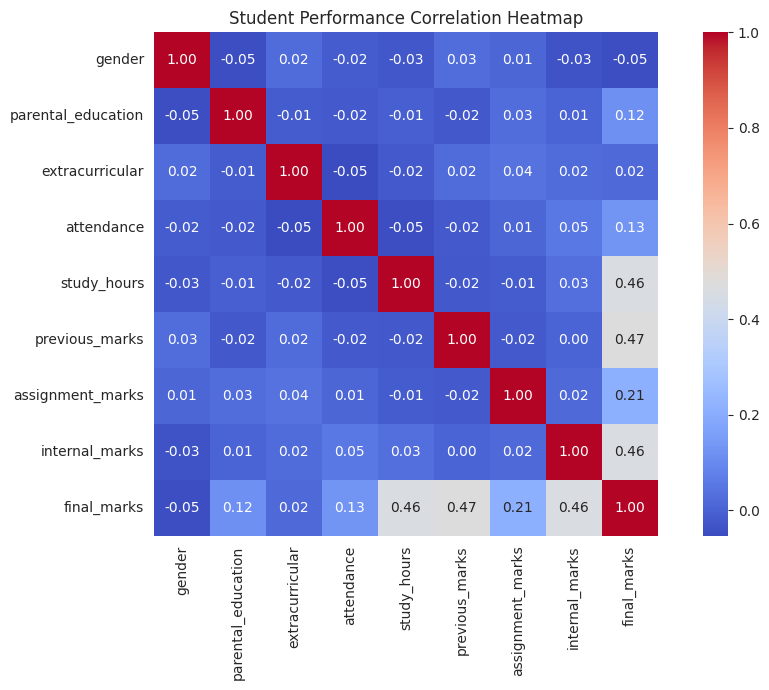

In [5]:

# CELL 5: CORRELATION HEATMAP

corr = df.drop(
    columns=["student_id", "pass_fail", "segment", "cluster"],
    errors="ignore"
).corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()
plt.show()


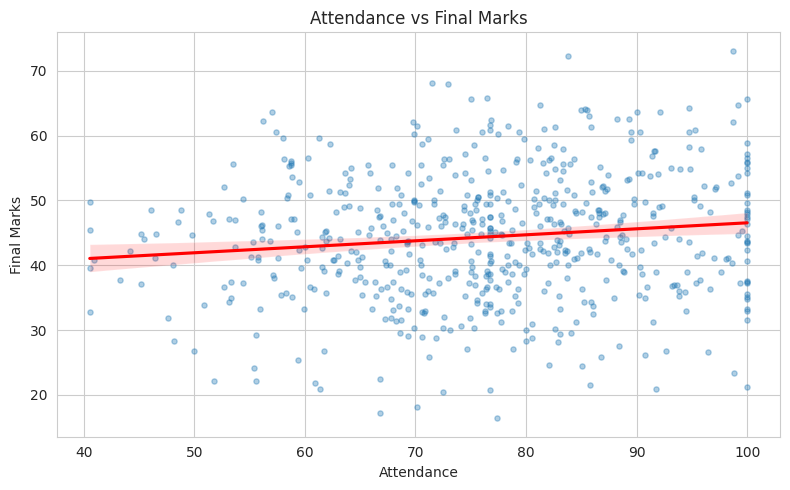

In [6]:

# CELL 6: ATTENDANCE VS FINAL MARKS

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="attendance",
    y="final_marks",
    scatter_kws={"alpha": 0.35, "s": 14},
    line_kws={"color": "red"}
)

plt.title("Attendance vs Final Marks")
plt.xlabel("Attendance")
plt.ylabel("Final Marks")

plt.tight_layout()
plt.show()


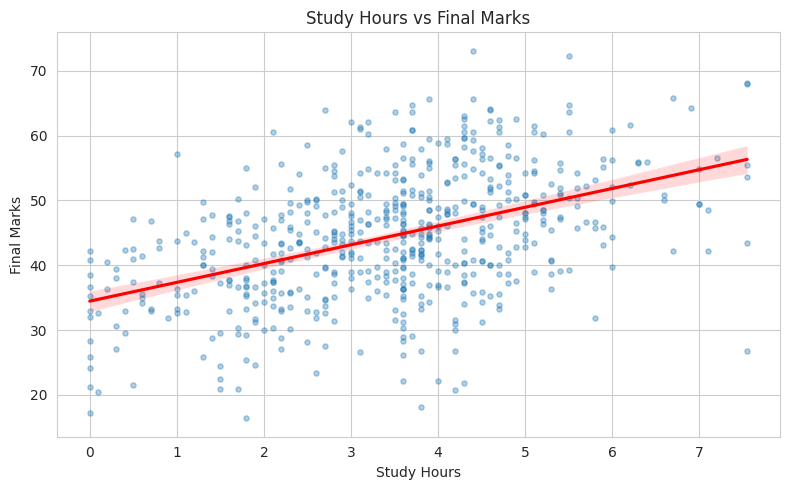

In [7]:

# CELL 7: STUDY HOURS VS FINAL MARKS

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="study_hours",
    y="final_marks",
    scatter_kws={"alpha": 0.35, "s": 14},
    line_kws={"color": "red"}
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")

plt.tight_layout()
plt.show()


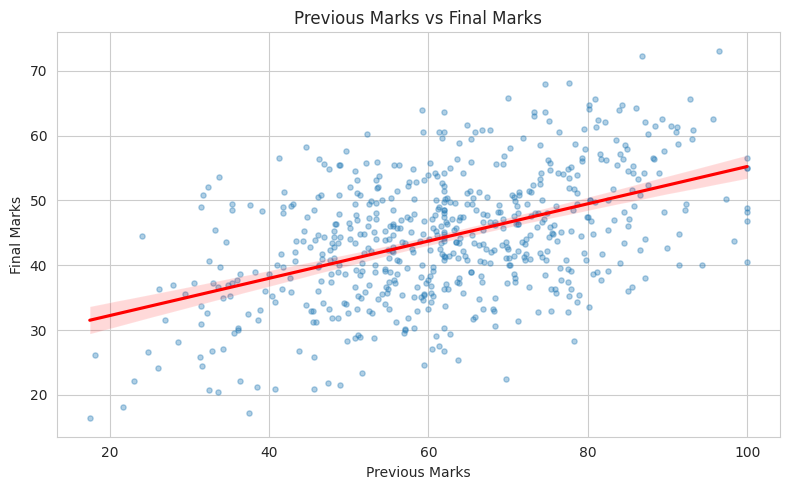

In [8]:

# CELL 8: PREVIOUS MARKS VS FINAL MARKS

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="previous_marks",
    y="final_marks",
    scatter_kws={"alpha": 0.35, "s": 14},
    line_kws={"color": "red"}
)

plt.title("Previous Marks vs Final Marks")
plt.xlabel("Previous Marks")
plt.ylabel("Final Marks")

plt.tight_layout()
plt.show()


In [9]:

# CELL 9: FEATURE SELECTION AND DATA SPLITTING

X = df[FEATURES].copy()

y_reg = df["final_marks"].copy()

y_clf = df["pass_fail"].copy()

# Check classification data
if y_clf.nunique() < 2:
    raise ValueError(
        "Pass/Fail dataset must contain both classes."
    )

if y_clf.value_counts().min() < 5:
    raise ValueError(
        "At least 5 records are required in each Pass/Fail class for 5-fold CV."
    )

# Train-Test Split
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = train_test_split(
    X,
    y_reg,
    y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

# Feature Scaling
scaler = StandardScaler()

Xs_tr = scaler.fit_transform(X_tr)

Xs_te = scaler.transform(X_te)

Xs_all = scaler.transform(X)

# Handle missing values
imputer = SimpleImputer(strategy="median")

Xs_tr_clean = imputer.fit_transform(Xs_tr)

Xs_te_clean = imputer.transform(Xs_te)

Xs_all_clean = imputer.transform(Xs_all)

# Cross Validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Training Records:", len(X_tr))

print("Testing Records:", len(X_te))

print("Feature Count:", len(FEATURES))

print("Data splitting and scaling completed!")


Training Records: 480
Testing Records: 120
Feature Count: 8
Data splitting and scaling completed!


LINEAR REGRESSION RESULTS
R2 Score: 0.728
MAE: 3.88
RMSE: 5.13
5-Fold CV R2: 0.708


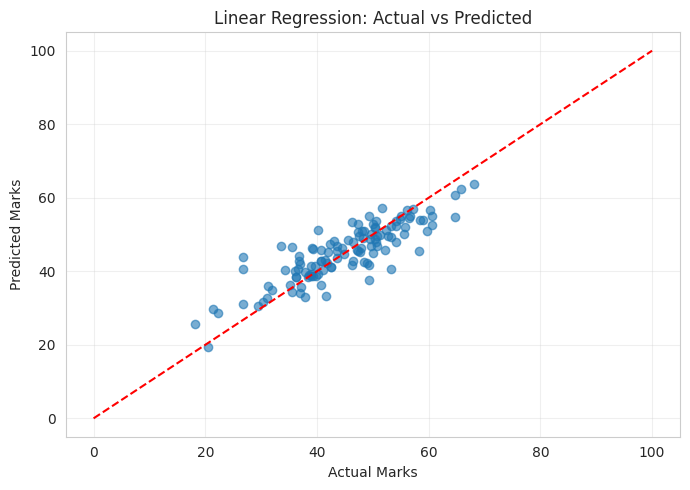

In [10]:

# CELL 10: LINEAR REGRESSION

lin = LinearRegression()

# Train Model
lin.fit(Xs_tr_clean, yr_tr)

# Predict Final Marks
pred_marks = lin.predict(Xs_te_clean)

# Model Evaluation
r2 = r2_score(yr_te, pred_marks)

mae = mean_absolute_error(yr_te, pred_marks)

rmse = np.sqrt(
    mean_squared_error(yr_te, pred_marks)
)

# Cross Validation
cv_scores = cross_val_score(
    lin,
    Xs_tr_clean,
    yr_tr,
    cv=kf,
    scoring="r2"
)

print("LINEAR REGRESSION RESULTS")

print("R2 Score:", round(r2, 3))

print("MAE:", round(mae, 2))

print("RMSE:", round(rmse, 2))

print("5-Fold CV R2:", round(cv_scores.mean(), 3))

# Actual vs Predicted Graph
plt.figure(figsize=(7, 5))

plt.scatter(
    yr_te,
    pred_marks,
    alpha=0.6
)

plt.plot(
    [0, 100],
    [0, 100],
    "r--"
)

plt.xlabel("Actual Marks")

plt.ylabel("Predicted Marks")

plt.title("Linear Regression: Actual vs Predicted")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


LOGISTIC REGRESSION RESULTS
Best C: 1
Test Accuracy: 0.842
CV Accuracy: 0.808

Classification Report:
              precision    recall  f1-score   support

        Fail       0.76      0.74      0.75        38
        Pass       0.88      0.89      0.88        82

    accuracy                           0.84       120
   macro avg       0.82      0.81      0.82       120
weighted avg       0.84      0.84      0.84       120



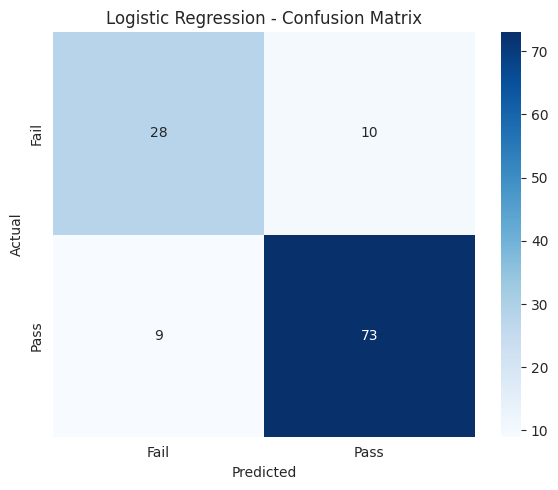

In [11]:

# CELL 11: LOGISTIC REGRESSION

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Hyperparameter Optimization
gs = GridSearchCV(
    model,
    {"C": [0.01, 0.1, 1, 10, 100]},
    cv=skf,
    scoring="f1"
)

gs.fit(Xs_tr_clean, yc_tr)

# Best Model
logit = gs.best_estimator_

# Prediction
pc = logit.predict(Xs_te_clean)

# Evaluation
logit_accuracy = accuracy_score(yc_te, pc)

cv_scores_logit = cross_val_score(
    logit,
    Xs_tr_clean,
    yc_tr,
    cv=skf,
    scoring="accuracy"
)

print("LOGISTIC REGRESSION RESULTS")

print("Best C:", gs.best_params_["C"])

print("Test Accuracy:", round(logit_accuracy, 3))

print(
    "CV Accuracy:",
    round(cv_scores_logit.mean(), 3)
)

print("\nClassification Report:")

print(
    classification_report(
        yc_te,
        pc,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    yc_te,
    pc,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Logistic Regression - Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.tight_layout()

plt.show()


KNN CLASSIFICATION RESULTS
Test Accuracy: 0.758

Classification Report:
              precision    recall  f1-score   support

        Fail       0.68      0.45      0.54        38
        Pass       0.78      0.90      0.84        82

    accuracy                           0.76       120
   macro avg       0.73      0.67      0.69       120
weighted avg       0.75      0.76      0.74       120



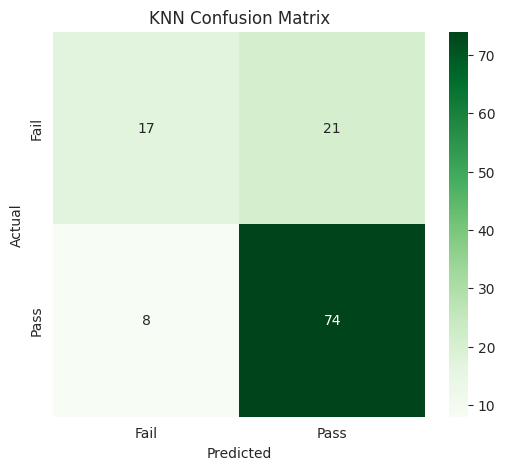


Five Similar Students:


,student_id,attendance,study_hours,previous_marks,assignment_marks,internal_marks,gender,parental_education,extracurricular,final_marks
521,S0522,87.0,4.1,66.9,81.2,59.7,0,1,1,47.9
38,S0039,83.9,3.0,62.0,94.5,37.8,0,0,1,44.8
175,S0176,75.0,2.2,72.1,94.6,52.4,0,0,1,43.3
182,S0183,82.6,2.3,57.0,77.5,33.3,0,1,1,30.2
418,S0419,85.7,0.5,70.0,93.2,54.3,0,1,1,42.5


In [12]:

# CELL 12: KNN CLASSIFICATION

knn = KNeighborsClassifier(
    n_neighbors=5
)

# Train KNN
knn.fit(Xs_tr_clean, yc_tr)

# Prediction
knn_pred = knn.predict(Xs_te_clean)

# Evaluation
knn_accuracy = accuracy_score(
    yc_te,
    knn_pred
)

print("KNN CLASSIFICATION RESULTS")

print("Test Accuracy:", round(knn_accuracy, 3))

print("\nClassification Report:")

print(
    classification_report(
        yc_te,
        knn_pred,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

# Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(yc_te, knn_pred, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("KNN Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


# SIMILAR STUDENT IDENTIFICATION

nearest = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean"
)

nearest.fit(Xs_tr_clean)

distances, indices = nearest.kneighbors(
    Xs_te_clean[:1]
)

similar_indices = X_tr.index[indices[0]]

similar_students = df.loc[similar_indices]

print("\nFive Similar Students:")

display(
    similar_students[
        ["student_id"] + FEATURES + ["final_marks"]
    ]
)


STUDENT PERFORMANCE SEGMENTATION


,attendance,study_hours,previous_marks,assignment_marks,internal_marks,final_marks
segment,,,,,,
At-Risk,72.52,2.33,61.83,70.13,50.26,38.68
Average,80.07,4.02,64.19,52.09,56.82,44.11
High Performing,77.85,4.08,60.84,74.19,73.58,51.21



Student Count:
segment
At-Risk            217
Average            193
High Performing    190
Name: count, dtype: int64


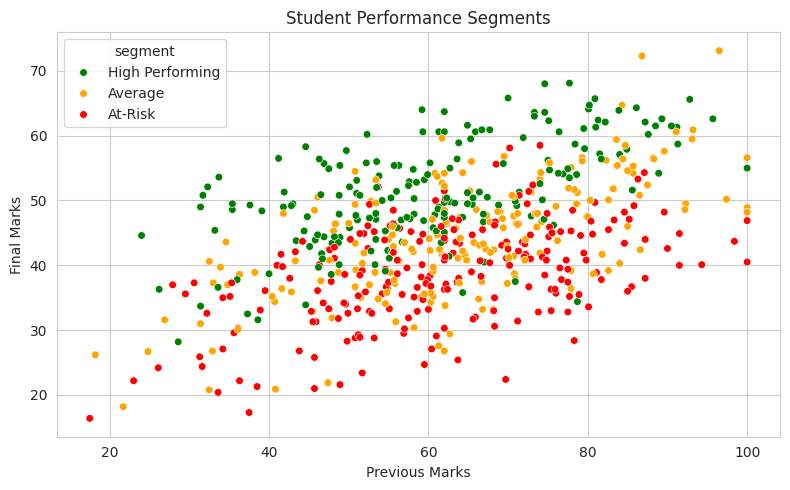

In [13]:

# CELL 13: K-MEANS CLUSTERING

clus_cols = NUM

# Separate scaler for clustering
cluster_scaler = StandardScaler()

Xc = cluster_scaler.fit_transform(
    df[clus_cols]
)

# Train K-Means
km = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

labels = km.fit_predict(Xc)

df["cluster"] = labels

# Identify cluster names by average marks
order = (
    df.groupby("cluster")["final_marks"]
    .mean()
    .sort_values()
    .index.tolist()
)

names = {
    order[0]: "At-Risk",
    order[1]: "Average",
    order[2]: "High Performing"
}

df["segment"] = df["cluster"].map(names)

# Display Results
print("STUDENT PERFORMANCE SEGMENTATION")

display(
    df.groupby("segment")[
        clus_cols + ["final_marks"]
    ].mean().round(2)
)

print("\nStudent Count:")

print(
    df["segment"].value_counts()
)

# Visualization
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="previous_marks",
    y="final_marks",
    hue="segment",
    hue_order=[
        "High Performing",
        "Average",
        "At-Risk"
    ],
    palette=[
        "green",
        "orange",
        "red"
    ],
    s=30
)

plt.title("Student Performance Segments")

plt.xlabel("Previous Marks")

plt.ylabel("Final Marks")

plt.tight_layout()

plt.show()


FEATURE IMPORTANCE RESULTS


,Feature,Importance
1,study_hours,0.445
2,previous_marks,0.418
4,internal_marks,0.304
3,assignment_marks,0.074
0,attendance,0.041
6,parental_education,0.030
5,gender,0.002
7,extracurricular,-0.000


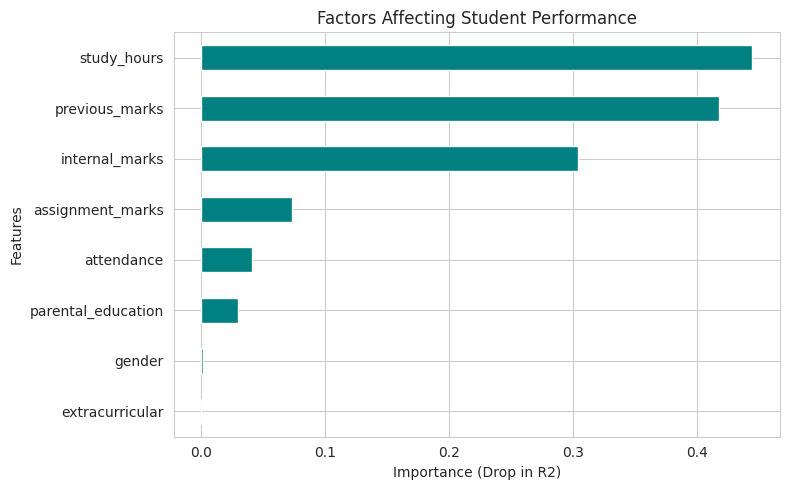

In [14]:

# CELL 14: FEATURE IMPORTANCE

perm = permutation_importance(
    lin,
    Xs_te_clean,
    yr_te,
    n_repeats=10,
    random_state=42,
    scoring="r2"
)

imp = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": perm.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

print("FEATURE IMPORTANCE RESULTS")

display(
    imp.round(3)
)

# Visualization
plt.figure(figsize=(8, 5))

imp.set_index("Feature")[
    "Importance"
].sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Factors Affecting Student Performance")

plt.xlabel("Importance (Drop in R2)")

plt.ylabel("Features")

plt.tight_layout()

plt.show()


STUDENT PREDICTION RESULTS


,student_id,predicted_final_marks,pass_probability,fail_probability,pass_fail_prediction,academic_risk,segment,actual_final_marks
0,S0001,56.2,0.993,0.007,Pass,Low,High Performing,55.0
1,S0002,52.2,0.968,0.032,Pass,Low,Average,54.2
2,S0003,53.1,0.970,0.030,Pass,Low,High Performing,47.5
3,S0004,42.6,0.650,0.350,Pass,Medium,Average,37.2
4,S0005,44.1,0.698,0.302,Pass,Medium,High Performing,43.4
5,S0006,63.2,0.999,0.001,Pass,Low,High Performing,68.0
6,S0007,40.0,0.423,0.577,Fail,Medium,High Performing,45.3
7,S0008,44.6,0.727,0.273,Pass,Low,High Performing,47.9
8,S0009,38.3,0.305,0.695,Fail,High,At-Risk,38.4
9,S0010,56.0,0.990,0.010,Pass,Low,Average,52.4


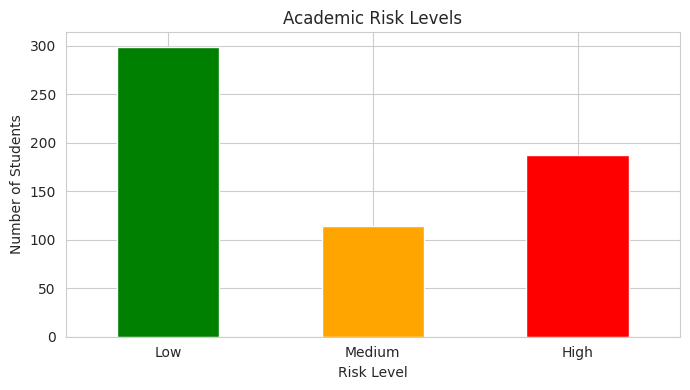

TOP 10 HIGHEST RISK STUDENTS


,student_id,predicted_final_marks,pass_probability,fail_probability,pass_fail_prediction,academic_risk,segment,actual_final_marks
511,S0512,18.3,0.001,0.999,Fail,High,At-Risk,24.2
512,S0513,20.0,0.001,0.999,Fail,High,Average,20.9
314,S0315,19.4,0.001,0.999,Fail,High,At-Risk,20.4
343,S0344,22.2,0.001,0.999,Fail,High,At-Risk,16.4
287,S0288,25.9,0.004,0.996,Fail,High,At-Risk,24.4
589,S0590,25.5,0.004,0.996,Fail,High,Average,18.2
56,S0057,24.8,0.004,0.996,Fail,High,At-Risk,32.6
11,S0012,25.1,0.004,0.996,Fail,High,At-Risk,22.2
18,S0019,24.8,0.004,0.996,Fail,High,At-Risk,17.3
571,S0572,26.4,0.006,0.994,Fail,High,Average,26.2


Student prediction CSV saved successfully!


In [15]:

# CELL 15: ACADEMIC RISK ANALYSIS

def risk_level(fail_prob):

    if fail_prob < 0.30:
        return "Low"

    elif fail_prob < 0.60:
        return "Medium"

    else:
        return "High"


# Prepare Results
res = df[["student_id"]].copy()

# Predict Final Marks
res["predicted_final_marks"] = np.clip(
    lin.predict(Xs_all_clean),
    0,
    100
).round(1)

# Pass Probability
prob_pass = logit.predict_proba(
    Xs_all_clean
)[:, 1]

res["pass_probability"] = prob_pass.round(3)

res["fail_probability"] = (1 - prob_pass).round(3)

# Pass/Fail Prediction
res["pass_fail_prediction"] = np.where(
    prob_pass >= 0.5,
    "Pass",
    "Fail"
)

# Academic Risk
res["academic_risk"] = [
    risk_level(1 - p)
    for p in prob_pass
]

# Student Segmentation
res["segment"] = df["segment"].values

# Actual Marks
res["actual_final_marks"] = df["final_marks"].values


print("STUDENT PREDICTION RESULTS")

display(res.head(10))


# Academic Risk Visualization
risk_counts = (
    res["academic_risk"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High"],
        fill_value=0
    )
)

plt.figure(figsize=(7, 4))

risk_counts.plot(
    kind="bar",
    color=["green", "orange", "red"],
    rot=0
)

plt.title("Academic Risk Levels")

plt.xlabel("Risk Level")

plt.ylabel("Number of Students")

plt.tight_layout()

plt.show()


# Highest Risk Students
print("TOP 10 HIGHEST RISK STUDENTS")

display(
    res.sort_values(
        "pass_probability"
    ).head(10)
)


# Save Results
res.to_csv(
    "student_predictions.csv",
    index=False
)

print("Student prediction CSV saved successfully!")


In [16]:

# CELL 16: NEW STUDENT PREDICTION

print("ENTER NEW STUDENT DETAILS")

student_id = input("Enter Student ID: ")

attendance = float(
    input("Enter Attendance (0-100): ")
)

study_hours = float(
    input("Enter Study Hours (0-16): ")
)

previous_marks = float(
    input("Enter Previous Marks (0-100): ")
)

assignment_marks = float(
    input("Enter Assignment Marks (0-100): ")
)

internal_marks = float(
    input("Enter Internal Marks (0-100): ")
)

gender = input(
    "Gender (Male/Female): "
).strip().title()

education = input(
    "Parent Education (School/Graduate/Postgraduate): "
).strip().title()

activity = input(
    "Extracurricular (Yes/No): "
).strip().title()


# Validate Input
if not 0 <= attendance <= 100:
    raise ValueError("Attendance must be between 0 and 100.")

if not 0 <= study_hours <= 16:
    raise ValueError("Study hours must be between 0 and 16.")

for value, field in [
    (previous_marks, "Previous Marks"),
    (assignment_marks, "Assignment Marks"),
    (internal_marks, "Internal Marks")
]:
    if not 0 <= value <= 100:
        raise ValueError(f"{field} must be between 0 and 100.")


# Convert Categorical Values
gender_map = {
    "Male": 0,
    "Female": 1
}

education_map = {
    "School": 0,
    "Graduate": 1,
    "Postgraduate": 2
}

activity_map = {
    "No": 0,
    "Yes": 1
}

if gender not in gender_map:
    raise ValueError("Enter Male or Female.")

if education not in education_map:
    raise ValueError("Enter School, Graduate or Postgraduate.")

if activity not in activity_map:
    raise ValueError("Enter Yes or No.")


gender = gender_map[gender]

education = education_map[education]

activity = activity_map[activity]


# Create Student DataFrame
new_student = pd.DataFrame(
    [[
        attendance,
        study_hours,
        previous_marks,
        assignment_marks,
        internal_marks,
        gender,
        education,
        activity
    ]],
    columns=FEATURES
)


# Apply Same Preprocessing
scaled = scaler.transform(new_student)

clean = imputer.transform(scaled)


# Linear Regression Prediction
marks = np.clip(
    lin.predict(clean)[0],
    0,
    100
)


# Logistic Regression Prediction
pass_prob = logit.predict_proba(clean)[0][1]

fail_prob = 1 - pass_prob

result = "Pass" if pass_prob >= 0.5 else "Fail"


# Academic Risk
risk = risk_level(fail_prob)


# K-Means Segmentation
cluster_data = cluster_scaler.transform(
    new_student[clus_cols]
)

cluster = km.predict(cluster_data)[0]

segment = names[cluster]


# KNN Prediction
knn_result = knn.predict(clean)[0]

knn_result = "Pass" if knn_result == 1 else "Fail"


# Final Output
print("\n======================================")

print("       STUDENT PREDICTION REPORT")

print("======================================")

print("Student ID:", student_id)

print("Predicted Final Marks:", round(marks, 2))

print("Pass Probability:", round(pass_prob * 100, 2), "%")

print("Fail Probability:", round(fail_prob * 100, 2), "%")

print("Logistic Regression Result:", result)

print("KNN Result:", knn_result)

print("Academic Risk:", risk)

print("Performance Segment:", segment)

print("======================================")


ENTER NEW STUDENT DETAILS
Enter Student ID: 0022
Enter Attendance (0-100): 56
Enter Study Hours (0-16): 10
Enter Previous Marks (0-100): 56
Enter Assignment Marks (0-100): 25
Enter Internal Marks (0-100): 45
Gender (Male/Female): MALE
Parent Education (School/Graduate/Postgraduate): Graduate
Extracurricular (Yes/No): No

       STUDENT PREDICTION REPORT
Student ID: 0022
Predicted Final Marks: 49.87
Pass Probability: 94.16 %
Fail Probability: 5.84 %
Logistic Regression Result: Pass
KNN Result: Pass
Academic Risk: Low
Performance Segment: Average


In [17]:

# CELL 17: SAVE ALL MODELS

import joblib
import os

os.makedirs("models", exist_ok=True)

# Store all trained models and preprocessing objects
models = {

    "linear_model": lin,

    "logistic_model": logit,

    "knn_model": knn,

    "nearest_neighbors": nearest,

    "kmeans_model": km,

    "scaler": scaler,

    "imputer": imputer,

    "cluster_scaler": cluster_scaler,

    "cluster_names": names,

    "features": FEATURES,

    "numeric_features": NUM,

    "cluster_columns": clus_cols,

    "pass_mark": PASS_MARK,

    "risk_thresholds": {
        "low": 0.30,
        "medium": 0.60
    },

    "model_metrics": {
        "linear_r2": r2,
        "linear_mae": mae,
        "linear_rmse": rmse,
        "logistic_accuracy": logit_accuracy,
        "knn_accuracy": knn_accuracy
    }
}

# Save all models in one file
joblib.dump(
    models,
    "models/student_model.pkl"
)

print("All models saved successfully!")

print("\nSaved File: models/student_model.pkl")

print("Total Models: 4")


All models saved successfully!

Saved File: models/student_model.pkl
Total Models: 4


In [20]:

# CELL 18: DOWNLOAD MODEL AND PREDICTION FILES

from google.colab import files

# Download trained models
files.download(
    "models/student_model.pkl"
)

# Download student prediction results
files.download(
    "student_predictions.csv"
)

print("Download completed!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download completed!


In [21]:
from google.colab import files

files.download("models/student_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
from google.colab import files

files.download("student_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>